# Ampere Leak | VoltRelay Energy

The saved charts and tables come from the verified local analysis.

**PyCharm.** Open this notebook from the project folder, select the project virtual environment as the kernel, and run all cells. The default source is the local dataset folder.

**Google Colab.** Upload the project and source data to My Drive. Running all cells mounts Drive before looking for the project. Use the overrides in the setup cell for custom paths.

In [3]:
import os

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "COLAB_GPU" in os.environ
if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")


In [4]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import subprocess
import sys

# Set either override when your files are stored in a different location.
PROJECT_OVERRIDE = ""
SOURCE_OVERRIDE = ""

drive_root = Path("/content/drive/MyDrive") if IN_COLAB else None
if PROJECT_OVERRIDE:
    projects = [Path(PROJECT_OVERRIDE).expanduser()]
elif IN_COLAB:
    projects = [drive_root / "ampere-leak", drive_root / "ampere-leak-final"]
else:
    projects = [Path.cwd(), *Path.cwd().parents]
project = next((p for p in projects if (p / "pipeline.py").is_file()), None)
if project is None:
    raise FileNotFoundError("Project code not found. Set PROJECT_OVERRIDE to the folder containing pipeline.py.")

required = ("pipeline.py", "report.py", "verify.py", "requirements.txt", "logo.png")
missing = [name for name in required if not (project / name).is_file()]
if missing:
    raise FileNotFoundError("Missing project files: " + ", ".join(missing))

def is_source(path):
    if path.is_file():
        return path.suffix.lower() == ".zip"
    return path.is_dir() and any(
        name in {"swap_events.csv", "swap_events.csv.gz"}
        for name in (file.name for file in path.rglob("swap_events.csv*"))
    )

candidates = [Path(SOURCE_OVERRIDE).expanduser()] if SOURCE_OVERRIDE else [
    project / "dataset",
    *sorted(project.glob("Hackathon Data Set*.zip")),
    *(sorted(drive_root.glob("Hackathon Data Set*.zip")) if IN_COLAB else []),
]
source = next((p for p in candidates if is_source(p)), None)
if source is None:
    raise FileNotFoundError("Dataset not found. Set SOURCE_OVERRIDE to the original ZIP or the folder containing the source CSVs.")

output_root = Path("/content") if IN_COLAB else project
run = output_root / datetime.now(timezone.utc).strftime("run-notebook-%Y%m%dT%H%M%S%f")
print("Project:", project)
print("Source:", source)
print("Run folder:", run)
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(project / "requirements.txt")], check=True)
else:
    from importlib.util import find_spec

    if find_spec("numpy") is None:
        raise ModuleNotFoundError("Select the project virtual environment or install requirements.txt in this kernel.")


Project: C:\Users\laksh\PycharmProjects\ampere-leak
Source: C:\Users\laksh\PycharmProjects\ampere-leak\dataset
Run folder: C:\Users\laksh\PycharmProjects\ampere-leak\run-notebook-20261115T180056520213


## Data understanding and cleaning
Eight synthetic relational tables cover January 2024 to June 2025. The fact grain is a swap attempt. The pipeline joins required dimensions, corrects documented timestamp shifts, excludes test stations and audits missing measurements. All published tables are aggregate evidence.

In [5]:
for file,args in [('pipeline.py',[source,run/'evidence']),('report.py',[run/'evidence',run/'deliverables']),('verify.py',[run/'evidence'])]:
    subprocess.run([sys.executable,'-B',str(project/file),*map(str,args)],check=True)
def rows(name):
    with (run/'evidence'/f'{name}.csv').open(encoding='utf-8') as handle:
        return list(csv.DictReader(handle))
from IPython.display import display, Markdown
def preview(name,n=10):
    data=rows(name)[:n]
    if data:
        keys=list(data[0]); lines=['| '+' | '.join(keys)+' |','| '+' | '.join(['---']*len(keys))+' |']
        lines.extend('| '+' | '.join(str(r[k]).replace('|','/').replace('<','&lt;') for k in keys)+' |' for r in data)
        display(Markdown(chr(10).join(lines)))
preview('forensic_audit',30)

| check | affected | denominator | percent | treatment |
| --- | --- | --- | --- | --- |
| event_test | 62031 | 3877013 | 1.599968841992534 | Exclude STN-TST prefix |
| firmware_shift | 139490 | 3814982 | 3.656373739115938 | Add 330 minutes in raw calendar window |
| offline_batch_rows | 591114 | 3814982 | 15.49454230714588 | Count configured offline sync mode |
| offline_batch_complete_key | 554075 | 591114 | 93.73403438253874 | Complete four-field identifier key |
| offline_duplicate | 0 | 3814982 | 0.0 | Keep latest success in each adjacent-gap cluster, otherwise latest state |
| outside_window | 0 | 3814982 | 0.0 | Exclude corrected timestamps outside study window |
| event_unmatched_dimension | 0 | 3814982 | 0.0 | Exclude missing rider or station joins |
| unknown_outcome | 0 | 3814982 | 0.0 | Retain separately as an unknown noncompletion |
| city_normalized | 585 | 20000 | 2.925 | Map aliases to network cities |
| city_unmapped | 0 | 20000 | 0.0 | Keep unknown category |
| soc_drift | 3634 | 3814982 | 0.09525601955657982 | Flag and cap upper bound for wear estimates |
| odometer_negative | 7687 | 3814982 | 0.2014950529255446 | Exclude from range summaries |
| odometer_upper | 37193 | 3814982 | 0.9749194098425629 | Exclude above completed-swap p99 within vehicle class |
| completed_missing_price | 0 | 3586675 | 0.0 | Track incomplete revenue coverage |
| completed_missing_energy | 0 | 3586675 | 0.0 | Track incomplete energy coverage |
| completed_wear_uncovered | 0 | 3586675 | 0.0 | Track incomplete wear coverage |
| completed_missing_returned_pack | 0 | 3586675 | 0.0 | Exclude from lot-level returns |
| noncompleted | 228307 | 3814982 | 5.98448433046342 | Preserve operational demand, zero recognized revenue |
| telemetry_test | 26256 | 1487712 | 1.7648577143963349 | Exclude test stations |
| telemetry_unmatched | 0 | 1461456 | 0.0 | Exclude missing station joins |
| telemetry_incomplete | 46131 | 1461456 | 3.1565096725457353 | Exclude non-ok telemetry from observed rates |
| stockout_2w_unobserved | 46131 | 1461456 | 3.1565096725457353 | Mask unknown 2W status |
| stockout_3w_unobserved | 811753 | 1461456 | 55.54412859504494 | Mask unknown 3W status |
| ticket_test | 535 | 44000 | 1.2159090909090908 | Exclude test stations |
| csat_missing | 28513 | 43465 | 65.59990797193144 | Report resolution strata and response rates |
| ticket_reclassified | 0 | 15111 | 0.0 | Unique bilingual phrase match |
| ticket_review | 15111 | 15111 | 100.0 | Unassigned, optional TF-IDF suggestion |

## Q1–Q3 · Network performance, service and geography
Use completion counts for financial rates and all attempts for failure rates. Compare all three half-year periods. For station and thermal views review the coverage and denominators alongside the estimated rates.

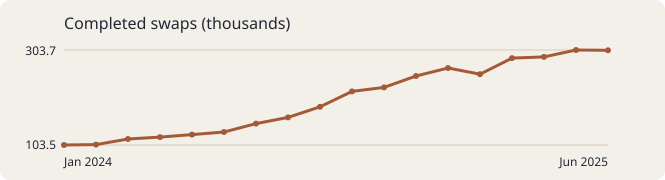

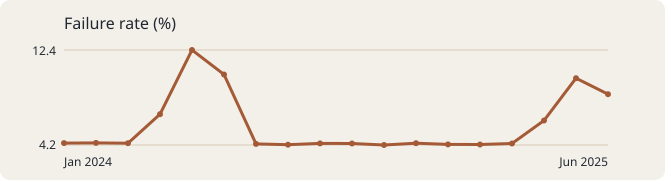

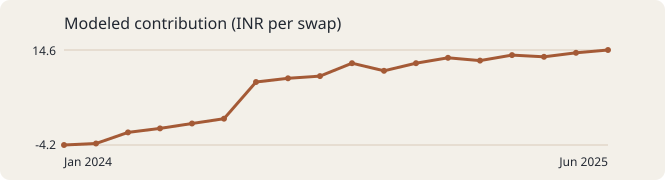

| component | 2024H1_inr_per_swap | 2025H1_inr_per_swap | delta_inr_per_swap |
| --- | --- | --- | --- |
| list_price | 64.41645349899507 | 69.5902978631366 | 5.17384436414153 |
| discount | -4.531423579398297 | -6.5304137311291335 | -1.9989901517308368 |
| pricing_residual | 0.00037827739300030905 | 1.7062645941152623 | 1.705886316722262 |
| energy | -21.56809398974226 | -18.137706672653824 | 3.430387317088435 |
| wear | -21.721309714060787 | -21.56070539537527 | 0.16060431868551817 |
| fixed_op_ex | -18.063927462086607 | -11.479692400452798 | 6.584235061633809 |

| station_id | city | wave | host | months_in_2025H1 | completed_h1 | attempts_h1 | no_pack_failures_h1 | contribution_h1 | observed_2w_hours_full_period | observed_2w_stockout_rate_full_period |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| STN-DEL-043 | Delhi NCR | Launch | mall_parking | 6 | 19918.0 | 22261.0 | 1486.0 | 328954.5884 | 11664.0 | 0.03429355281207133 |
| STN-HYD-072 | Hyderabad | Launch | kirana | 6 | 21896.0 | 24240.0 | 1475.0 | 356109.0655 | 13004.0 | 0.015918179021839434 |
| STN-DEL-050 | Delhi NCR | Launch | fuel_retailer | 6 | 19876.0 | 22167.0 | 1444.0 | 337129.4396 | 11672.0 | 0.03461274845784784 |
| STN-JAI-141 | Jaipur | Launch | mall_parking | 6 | 16903.0 | 18990.0 | 1322.0 | 253160.74599999998 | 12987.0 | 0.02918302918302918 |
| STN-JAI-138 | Jaipur | Launch | kirana | 6 | 17249.0 | 19250.0 | 1284.0 | 264101.449 | 11687.0 | 0.03910327714554633 |
| STN-HYD-070 | Hyderabad | Launch | kirana | 6 | 19444.0 | 21380.0 | 1217.0 | 298574.23600000003 | 12989.0 | 0.009238586496266072 |
| STN-JAI-137 | Jaipur | Launch | owned_lot | 6 | 16549.0 | 18503.0 | 1216.0 | 257568.2745 | 12610.0 | 0.07034099920697859 |
| STN-JAI-140 | Jaipur | Launch | mall_parking | 6 | 15550.0 | 17357.0 | 1177.0 | 198921.4406 | 12617.0 | 0.02932551319648094 |

| wave | stations | station_months | completed | completed_per_station_month | no_pack_failures | contribution |
| --- | --- | --- | --- | --- | --- | --- |
| Launch | 90 | 540 | 1157127.0 | 2142.8277777777776 | 53310.0 | 15748804.0759 |
| Wave1_2024H2 | 30 | 179 | 311452.0 | 1739.95530726257 | 9583.0 | 3711968.0788 |
| Wave2_2025H1 | 30 | 120 | 232840.0 | 1940.3333333333333 | 6868.0 | 3658184.5193 |

| metric | city_generation_hour_strata | weighted_hot_minus_cool |
| --- | --- | --- |
| mean_charge_minutes | 116 | 28.656542015506496 |
| mean_quarantined | 116 | 0.002564113832346847 |
| 2w_stockout_probability | 116 | 0.15190615793278098 |

In [6]:
from IPython.display import SVG
monthly = rows("monthly")
for field, label, scale in [
    ("completed", "Completed swaps (thousands)", .001),
    ("failure_rate", "Failure rate (%)", 100),
    ("contribution_per_swap", "Modeled contribution (INR per swap)", 1)
]:
    values = [float(r[field])*scale for r in monthly]
    lo, hi = min(values), max(values)
    coords = [(64 + i*32, 145 - (v-lo)/(hi-lo)*95) for i,v in enumerate(values)]
    line = " ".join(f"{x},{y:.1f}" for x,y in coords)
    markers = "".join(f'<circle cx="{x}" cy="{y:.1f}" r="3" fill="#a45a36"/>' for x,y in coords)
    display(SVG(data=f"""<svg xmlns="http://www.w3.org/2000/svg" width="665" height="180" viewBox="0 0 665 180">
    <rect width="665" height="180" rx="10" fill="#f3f0e9"/>
    <g font-family="sans-serif" fill="#212731">
    <text x="64" y="29" font-size="16">{label}</text>
    <text x="56" y="55" text-anchor="end" font-size="12">{hi:.1f}</text>
    <text x="56" y="149" text-anchor="end" font-size="12">{lo:.1f}</text>
    <text x="64" y="166" font-size="12">Jan 2024</text>
    <text x="608" y="166" text-anchor="end" font-size="12">Jun 2025</text></g>
    <path d="M64 50H608 M64 145H608" stroke="#d9caba" fill="none"/>
    <polyline points="{line}" stroke="#a45a36" stroke-width="3" fill="none"/>{markers}</svg>"""))
preview("margin_bridge")
preview("station_priority", 8)
preview("expansion_waves")
preview("thermal_stratified")

## Q4–Q6 · Equipment, pricing and retention
The pack-range metric requires matching an immediately preceding issue to a same-pack return. Pricing is an observational city comparison. Return models use first-week exposures and a later eligibility window. None of these comparisons alone identifies a causal effect.

In [7]:
preview('matched_pack_coverage'); preview('supplier_summary'); preview('pricing_did'); preview('fleet_economics',6); preview('retention_logit',7)

| check | rows |
| --- | --- |
| completed_records | 3586675 |
| matched_pack_return | 1135 |
| valid_discharge_and_distance | 1121 |

| supplier | pack_type | packs | returns | retired_share | mean_return_soh | mean_snapshot_soh_loss |
| --- | --- | --- | --- | --- | --- | --- |
| Amptek | 2W_2.1kWh | 1098.0 | 665575.0 | 0.0 | 89.72296179994741 | 19.235792349726776 |
| Amptek | 3W_4.8kWh | 209.0 | 79380.0 | 0.0 | 93.00446460065508 | 12.690909090909091 |
| Cellora | 2W_2.1kWh | 3035.0 | 1839541.0 | 0.0 | 89.71582459972352 | 19.210807248764414 |
| Cellora | 3W_4.8kWh | 520.0 | 196914.0 | 0.0 | 92.99469870095575 | 12.674615384615384 |
| Kyron | 2W_2.1kWh | 1385.0 | 709295.0 | 1.0 | 80.65348465730055 | 38.66519855595668 |
| Kyron | 3W_4.8kWh | 253.0 | 95970.0 | 0.20948616600790515 | 90.45804626445764 | 17.89881422924901 |

| treated | post_from | effect_peak_share | permutation_tail_fraction | placebo_assignments |
| --- | --- | --- | --- | --- |
| Bengaluru/Pune | 2024-10-01 | -0.030276981163638916 | 0.06666666666666667 | 15 |

| partner_id | name | revenue | completed | modeled_contribution | working_capital_cost | adjusted_contribution | adjusted_per_swap | peak_billable | payment_days |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| FP-01 | FeastFly | 32027884.5 | 516367.0 | 5256972.1704 | 315891.4635616438 | 4941080.706838356 | 9.568931993791928 | Y | 30 |
| FP-03 | ZipDrop | 28606514.800043 | 549390.0 | -633099.7324999999 | 423219.67101433483 | -1056319.4035143347 | -1.9227131973904417 | N | 45 |
| FP-02 | ParcelNest | 16740212.75 | 296209.0 | 1413250.6831 | 165108.94767123286 | 1248141.7354287673 | 4.213719824275317 | Y | 30 |
| FP-05 | Swiggle Go | 14092428.899946 | 237632.0 | 1684054.1066 | 138993.8192871386 | 1545060.2873128615 | 6.501903309793553 | N | 30 |
| FP-04 | CargoTuk | 13062630.799977 | 131334.0 | 559989.1269 | 128836.9065203211 | 431152.22037967894 | 3.2828682624429235 | Y | 30 |
| FP-07 | QuickCart | 7934508.550017 | 127961.0 | 1347374.145 | 78258.16652071562 | 1269115.9784792843 | 9.917990469590611 | Y | 30 |

| feature | coefficient | adjusted_odds_ratio | approx_lower | approx_upper |
| --- | --- | --- | --- | --- |
| intercept | 1.0978558521691069 | 2.997731548580883 | 1.7141363870175041 | 5.242520084993314 |
| early_stockout | -0.575464200018441 | 0.5624437218133876 | 0.48094845060980873 | 0.6577481220829277 |
| early_long_queue | 0.1403773598578022 | 1.1507079479244608 | 0.9809662192314011 | 1.3498209779884107 |
| early_low_soh | -0.13430317140200468 | 0.8743249540962615 | 0.6767948326973275 | 1.1295064448243213 |
| near_competitor | -0.008083635436763882 | 0.991948949284058 | 0.6798858092790887 | 1.4472470296579412 |
| early_competitor_promo | -0.23109029961536023 | 0.7936677949027501 | 0.5152957048202662 | 1.222421539270358 |
| first_week_attempts_cap10 | 0.276614124064742 | 1.3186574346772364 | 1.272183225221177 | 1.3668293965495721 |

## Key findings and action
Unit economics improved year over year, while failures worsened from the preceding half. No charged pack was the largest observed failure category. Test targeted battery float at matched hubs and validate recovery, contribution and rider returns before approving a rollout. Financial scenarios are illustrative and use editable assumptions.

In [8]:
preview("roi_scenarios", 18)
print("Output folder:", run / "deliverables")
print("Open analysis_report.html or scorecard.html to review the results.")

# Set to True and rerun this cell to download a ZIP of the verified run.
DOWNLOAD_RESULTS = False
if IN_COLAB and DOWNLOAD_RESULTS:
    import shutil
    from google.colab import files

    files.download(shutil.make_archive(str(run), "zip", run))


| case | option | capex | recovered_swaps_month | gross_gain_month | net_gain_month | payback_months | year1_roi | failure_rate_pp_improvement_at_fixed_demand |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| downside | Broad station expansion | 6000000 | 1162.6833333333334 | 29145.8396167545 | -470854.1603832455 |  | -1.9417083207664911 | 0.38340963676634665 |
| downside | Targeted co-location | 2400000 | 887.4541666666667 | 22246.467346127934 | -127753.53265387207 |  | -1.6387676632693604 | 0.29264931381870746 |
| downside | Targeted battery float and quarantine | 650000 | 760.6750000000001 | 19068.400582395378 | -931.5994176046224 |  | -1.0171987584788547 | 0.25084226898746353 |
| downside | Fleet-wide battery purchase | 3000000 | 1453.3541666666667 | 36432.299520943125 | -53567.700479056875 |  | -1.2142708019162276 | 0.4792620459579333 |
| downside | Network pricing rollout | 300000 | 0 | 0.0 | -25000.0 |  | -2.0 | 0.0 |
| downside | Fleet exclusive with incremental concession | 0 | 0 | -23838.762333369166 | -23838.762333369166 |  |  | 0.0 |
| base | Broad station expansion | 6000000 | 2325.366666666667 | 58291.679233509 | -441708.320766491 |  | -1.883416641532982 | 0.7668192735326933 |
| base | Targeted co-location | 2400000 | 1774.9083333333333 | 44492.93469225587 | -105507.06530774414 |  | -1.5275353265387208 | 0.5852986276374149 |
| base | Targeted battery float and quarantine | 650000 | 1521.3500000000001 | 38136.801164790755 | 18136.801164790755 | 35.8387344104458 | -0.66516674772694 | 0.5016845379749271 |
| base | Fleet-wide battery purchase | 3000000 | 2906.7083333333335 | 72864.59904188625 | -17135.40095811375 |  | -1.0685416038324551 | 0.9585240919158666 |
| base | Network pricing rollout | 300000 | 0 | 0.0 | -25000.0 |  | -2.0 | 0.0 |
| base | Fleet exclusive with incremental concession | 0 | 0 | -47677.52466673833 | -47677.52466673833 |  |  | 0.0 |
| upside | Broad station expansion | 6000000 | 3488.0500000000006 | 87437.51885026351 | -412562.4811497365 |  | -1.825124962299473 | 1.1502289102990402 |
| upside | Targeted co-location | 2400000 | 2662.3624999999997 | 66739.4020383838 | -83260.5979616162 |  | -1.416302989808081 | 0.8779479414561223 |
| upside | Targeted battery float and quarantine | 650000 | 2282.025 | 57205.201747186125 | 37205.201747186125 | 17.47067532160769 | -0.3131347369750254 | 0.7525268069623906 |
| upside | Fleet-wide battery purchase | 3000000 | 4360.0625 | 109296.89856282937 | 19296.898562829374 | 155.46539721044843 | -0.9228124057486825 | 1.4377861378738 |
| upside | Network pricing rollout | 300000 | 0 | 0.0 | -25000.0 |  | -2.0 | 0.0 |
| upside | Fleet exclusive with incremental concession | 0 | 0 | -71516.28700010749 | -71516.28700010749 |  |  | 0.0 |

Output folder: C:\Users\laksh\PycharmProjects\ampere-leak\run-notebook-20261115T180056520213\deliverables
Open analysis_report.html or scorecard.html to review the results.
